In [1]:
import yaml
import warnings
import sys

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as pl
import seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm
from sklearn.metrics import roc_curve
from matplotlib.cm import get_cmap

# make figures paper quality
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# load functions from ../utils
sys.path.append('../utils')
from utils import get_nnmd, annotate_essentiality

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
TEMPDIR = Path(config['TEMPDIR'])
cell_line_dict=config['cell_lines']
cell_lines = list(cell_line_dict.values())
cell_line_colors=config['cell_line_colors']

In [2]:
# Load DepMap data
df = pd.read_csv("../resources/DepMap/DepMap_24Q4_CRISPR_RNAi_SYM101.csv", index_col=1)
df = df.loc[:, (~df.isna()).sum(0) != 0]  # remove all-nan columns
df.index = df.index.str.replace("NCI", "")

In [3]:
df


,depmap_id,lineage_1,lineage_2,lineage_3,"CRISPR (DepMap Public 24Q4+Score, Chronos) A1BG","CRISPR (DepMap Public 24Q4+Score, Chronos) A1CF","CRISPR (DepMap Public 24Q4+Score, Chronos) A2M","CRISPR (DepMap Public 24Q4+Score, Chronos) A2ML1","CRISPR (DepMap Public 24Q4+Score, Chronos) A3GALT2","CRISPR (DepMap Public 24Q4+Score, Chronos) A4GALT",...,"RNAi (DRIVE, DEMETER2) RBX1","RNAi (DRIVE, DEMETER2) CDC42","RNAi (DRIVE, DEMETER2) RCE1","RNAi (DRIVE, DEMETER2) HNRNPDL","RNAi (DRIVE, DEMETER2) DMTF1","RNAi (DRIVE, DEMETER2) PPP4R1","RNAi (DRIVE, DEMETER2) CDH1","RNAi (DRIVE, DEMETER2) PTBP3","RNAi (DRIVE, DEMETER2) KCNE2","RNAi (DRIVE, DEMETER2) CASP8AP2"
cell_line_display_name,,,,,,,,,,,,,,,,,,,,,
A549,ACH-000681,Lung,Non-Small Cell Lung Cancer,Lung Adenocarcinoma,-0.105894,-0.011481,0.004970,0.017890,-0.034404,-0.141291,...,-1.726331,0.009322,-0.025797,-0.100949,-0.006433,-0.028276,-0.055418,-0.414615,0.031194,-0.425915
H1299,ACH-000510,Lung,Non-Small Cell Lung Cancer,Large Cell Lung Carcinoma,-0.042119,-0.042134,-0.018689,0.038864,-0.031952,0.044293,...,-1.827748,-0.905985,0.017159,-0.066058,-0.088608,-0.116749,-0.005625,-0.112230,0.039325,-0.438915
H1975,ACH-000587,Lung,Non-Small Cell Lung Cancer,Lung Adenocarcinoma,0.007617,-0.109286,0.031191,0.124409,-0.098701,-0.077552,...,-2.893821,-0.436538,0.255794,-0.556015,0.159989,0.176906,0.092378,-0.102944,-0.003241,-0.841914
HT29,ACH-000552,Bowel,Colorectal Adenocarcinoma,Colon Adenocarcinoma,-0.015563,0.041419,-0.016422,0.094946,0.028386,0.036329,...,-1.538919,0.136393,0.073900,NaN,0.128309,-0.094258,-0.265467,-0.742056,NaN,-0.532441


In [4]:
# Define Feature Types
columns = df.columns
lineage = columns.str.startswith("lineage")
aneu = columns.str.startswith("Aneuploidy")
arm = columns.str.startswith("Arm-level CNAs")
cn = columns.str.startswith("Copy Number (Absolute)")
cnp = columns.str.startswith("Copy Number Public 24Q4")
crico = columns.str.startswith("CRISPR confounders")
bcexp = columns.str.startswith("Batch corrected Expression Public 24Q4")
exp = columns.str.startswith("Expression Public 24Q4")
cri_chronos = columns.str.startswith("CRISPR (DepMap Public 24Q4+Score, Chronos)")
cri_ps_ceres = columns.str.startswith("CRISPR (Project Score, CERES)")
cri_ps_chronos = columns.str.startswith("CRISPR (Project Score, Chronos)")
rnai_1 = columns.str.startswith("RNAi (Achilles+DRIVE+Marcotte, DEMETER2)")
rnai_2 = columns.str.startswith("RNAi (Achilles, DEMETER2)")
rnai_3 = columns.str.startswith("RNAi (DRIVE, DEMETER2)")

In [5]:
# Load our data (MAGeCK scores)
tab = pd.read_csv('../results/merged/gene_results_perline.csv', index_col=0, header=[0, 1])
tab = tab.loc[:, (slice(None), 'MAGeCK_filtered_score')]
tab.columns = tab.columns.droplevel(1)
tab = tab.T
# tab.columns = 'SYMPHONY_' + tab.columns

# ROCs and NNMDs

In [6]:
# Depmap Corrected Scores
df_ = df.loc[:, cri_chronos]
df_.columns = df_.columns.str.replace("CRISPR (DepMap Public 24Q4+Score, Chronos) ", "", regex=False)

# Without correction
unc_df = pd.read_csv("../resources/DepMap/DepMap_SYM101_CRISPRGeneEffectUncorrected.csv", index_col=0)

In [7]:
# merge all
super_df = pd.concat({'SYMPHONY': tab, 'DepMap Chronos': df_, 'DepMap uncorrected': unc_df}, axis=1, join='inner')

# Common genes
gene_overlap = list(set(tab.columns) & set(df_.columns))

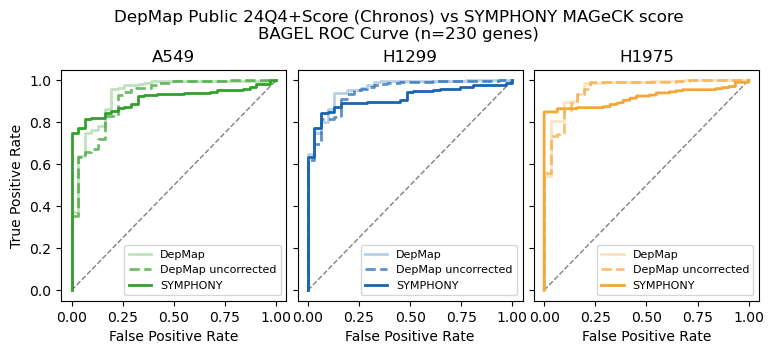

In [39]:
# Plot ROC curves for SYMPHONY vs DepMap; across all our cell lines
fig, axs = pl.subplots(1, 3, figsize=(3*3,3), sharey=True, gridspec_kw={'wspace': 0.05})
cmap = get_cmap('Paired')

data = {}
from sklearn.metrics import roc_auc_score
for ax, line in zip(axs, ['A549', 'H1299', 'H1975']):
    color = cell_line_colors[line]
    # DepMap
    sdf = super_df.loc[[line], 'DepMap Chronos'].T
    sdf.columns = ['score']
    sdf['essentiality'] = annotate_essentiality(sdf.index)
    mask = (sdf.essentiality!='unknown') & (sdf.index.isin(gene_overlap))
    fpr, tpr, thresholds = roc_curve(sdf[mask].essentiality=='essential', -sdf[mask].score)
    style ='-'
    auc = roc_auc_score(sdf[mask].essentiality=='essential', -sdf[mask].score)
    nnmd = get_nnmd(sdf, score_column='score')
    data[(line, 'DepMap')] = {'fpr': fpr, 'tpr': tpr, 'auc': auc, 'nnmd': nnmd}
    alpha=0.3
    ax.plot(fpr, tpr, label=f"DepMap", linewidth=2, linestyle=style, color=color, alpha=alpha)
    
    # DepMap uncorrected
    sdf = super_df.loc[[line], 'DepMap uncorrected'].T
    sdf.columns = ['score']
    sdf['essentiality'] = annotate_essentiality(sdf.index)
    mask = (sdf.essentiality!='unknown') & (sdf.index.isin(gene_overlap))
    fpr, tpr, thresholds = roc_curve(sdf[mask].essentiality=='essential', -sdf[mask].score)
    style ='--'
    auc = roc_auc_score(sdf[mask].essentiality=='essential', -sdf[mask].score)
    nnmd = get_nnmd(sdf, score_column='score')
    data[(line, 'DepMap uncorrected')] = {'fpr': fpr, 'tpr': tpr, 'auc': auc, 'nnmd': nnmd}
    alpha=0.7
    ax.plot(fpr, tpr, label=f"DepMap uncorrected", linewidth=2, linestyle=style, color=color, alpha=alpha)
    
    # SYMPHONY
    sdf = super_df.loc[[line], 'SYMPHONY'].T
    sdf.columns = ['score']
    sdf['essentiality'] = annotate_essentiality(sdf.index)
    mask = (sdf.essentiality!='unknown') & (sdf.index.isin(gene_overlap))
    fpr, tpr, thresholds = roc_curve(sdf[mask].essentiality=='essential', -sdf[mask].score)
    style ='-'
    auc = roc_auc_score(sdf[mask].essentiality=='essential', -sdf[mask].score)
    nnmd = get_nnmd(sdf, score_column='score')
    data[(line, 'SYMPHONY')] = {'fpr': fpr, 'tpr': tpr, 'auc': auc, 'nnmd': nnmd}
    alpha=1
    ax.plot(fpr, tpr, label=f"SYMPHONY", linewidth=2, linestyle=style, color=color, alpha=alpha)
    
    ax.legend(fontsize=8, loc='lower right')
    ax.set_xlabel('False Positive Rate')
    if ax == axs[0]: ax.set_ylabel('True Positive Rate')
    ax.set_title(line)
    
    # Add diagonal line
    ax.plot([0, 1], [0, 1], linestyle='--', color='grey', linewidth=1, zorder=-1)
pl.suptitle(f'DepMap Public 24Q4+Score (Chronos) vs SYMPHONY MAGeCK score\nBAGEL ROC Curve (n={(mask).sum()} genes)', y=1.08, fontsize=12)
pl.savefig(f'../results/figures/depmap_vs_symphony_ROCAUC.pdf', bbox_inches='tight', dpi=300)
pd.DataFrame(data).T.to_csv('../results/source_tables/Fig2ab_source_data.csv')
pl.show()


In [30]:
# AUC & NNMDscores
from sklearn.metrics import roc_auc_score
aucs = {}
nnmds = {}
for line in ['A549', 'H1299', 'H1975']:
    # DepMap
    sdf = super_df.loc[[line], 'DepMap Chronos'].T
    sdf.columns = ['score']
    sdf['essentiality'] = annotate_essentiality(sdf.index)
    mask = (sdf.essentiality!='unknown') & (sdf.index.isin(gene_overlap))
    aucs[(line, 'DepMap')] = roc_auc_score(sdf[mask].essentiality=='essential', -sdf[mask].score)
    nnmds[(line, 'DepMap')] = get_nnmd(sdf, score_column='score')
    
    # DepMap
    sdf = super_df.loc[[line], 'DepMap uncorrected'].T
    sdf.columns = ['score']
    sdf['essentiality'] = annotate_essentiality(sdf.index)
    mask = (sdf.essentiality!='unknown') & (sdf.index.isin(gene_overlap))
    aucs[(line, 'DepMap uncorrected')] = roc_auc_score(sdf[mask].essentiality=='essential', -sdf[mask].score)
    nnmds[(line, 'DepMap uncorrected')] = get_nnmd(sdf, score_column='score')
    
    # SYMPHONY
    sdf = super_df.loc[[line], 'SYMPHONY'].T
    sdf.columns = ['score']
    sdf['essentiality'] = annotate_essentiality(sdf.index)
    mask = (sdf.essentiality!='unknown') & (sdf.index.isin(gene_overlap))
    aucs[(line, 'SYMPHONY')] = roc_auc_score(sdf[mask].essentiality=='essential', -sdf[mask].score)
    nnmds[(line, 'SYMPHONY')] = get_nnmd(sdf, score_column='score')
auc_df = pd.DataFrame(aucs, index=['AUC']).T.reset_index().rename(columns={'level_0':'line', 'level_1':'origin'})
nnmd_df = pd.DataFrame(nnmds, index=['NNMD']).T.reset_index().rename(columns={'level_0':'line', 'level_1':'origin'})

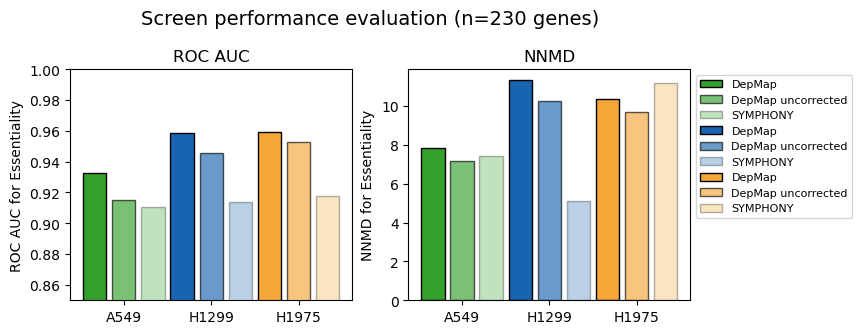

In [31]:
fig, axs = pl.subplots(1, 2, figsize=(4*2,3), gridspec_kw=dict(hspace=0.7))
for ax, D in zip(axs, [auc_df, nnmd_df]):
    for i, line in enumerate(D.line.unique()):
        for j, origin in enumerate(D.origin.unique()):
            ax.bar(3*i + j, D.set_index(['line', 'origin']).loc[line, origin], 
                   color=cell_line_colors[line], 
                   alpha = 1 - 0.35*j, 
                   label=origin,
                   edgecolor='black', linewidth=1
                   )
    if ax==axs[0]: ax.set_ylim(0.85, 1)
    ax.set_xticks([1, 4, 7])
    ax.set_xticklabels(D.line.unique())
ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))
axs[0].set_title('ROC AUC')
axs[0].set_ylabel('ROC AUC for Essentiality')
axs[1].set_title('NNMD')
axs[1].set_ylabel('NNMD for Essentiality')
pl.suptitle(f'Screen performance evaluation (n={mask.sum()} genes)', fontsize=14, y=1.08)
pl.savefig(f'../results/figures/depmap_vs_symphony_ROCAUC_NNDM_barplots.pdf', bbox_inches='tight', dpi=300)
pl.show()

# Which known non/ess genes are most different? Can we explain why they are different?

In [8]:
# Load our data (MAGeCK scores)
tab = pd.read_csv('../results/merged/gene_results_perline.csv', index_col=0, header=[0, 1])
tab = tab.loc[:, (slice(None), 'MAGeCK_filtered_lfc')]
tab.columns = tab.columns.droplevel(1)
tab = tab.T

# GEX
gex = pd.read_csv("../resources/DepMap/DepMap_Expression_Public_24Q4_subsetted.csv", index_col=1).iloc[:, 6:]
gex.index = gex.index.str.replace("NCI", "")
gex = gex.drop("HT29", axis=0)

# Depmap Corrected Scores
df_ = df.loc[:, cri_chronos]
df_.columns = df_.columns.str.replace("CRISPR (DepMap Public 24Q4+Score, Chronos) ", "", regex=False)

# Without correction
unc_df = pd.read_csv("../resources/DepMap/DepMap_SYM101_CRISPRGeneEffectUncorrected.csv", index_col=0)

In [9]:
super_df_ = pd.concat({'SYMPHONY': tab, 'DepMap Chronos': df_, 'DepMap uncorrected': unc_df, 'gex': gex}, axis=0, join='inner').T
super_df_['essentiality'] = annotate_essentiality(super_df_.index)
ddr_genes = pd.read_csv('../resources/HALLMARK_DNA_REPAIR.v2023.2.Hs.tsv', sep='\t', index_col=0).loc['GENE_SYMBOLS'][0].split(',')
super_df_['ddr'] = super_df_.index.isin(ddr_genes)
super_df_['ddr'] = super_df_['ddr'].replace({True: 'DDR', False: 'Non-DDR'})

In [10]:
# linear regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

def linear_regression(x, y):
    # Fit the model
    model = LinearRegression()
    model.fit(super_df_[[x]], super_df_[[y]])

    # Make predictions
    y_pred = model.predict(super_df_[[x]])

    # Calculate R^2 and RMSE
    r2 = r2_score(super_df_[[y]], y_pred)
    mse = mean_squared_error(super_df_[[y]], y_pred)
    rmse = np.sqrt(mse)
    # Calculate distance of predictions from the line y=x
    distances = np.abs(np.squeeze(y_pred) - super_df_[[y]].values.flatten())

    return r2, rmse, distances

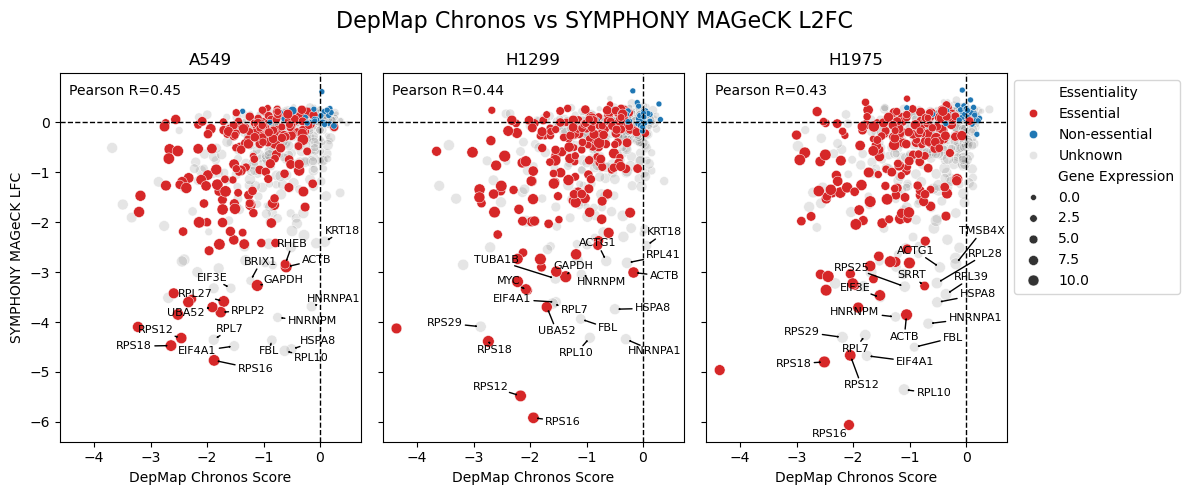

In [41]:
from adjustText import adjust_text
fig, axs = pl.subplots(1, 3, figsize=(4*3,5), sharex=True, sharey=True)
for line, ax in zip(['A549', 'H1299', 'H1975'], axs):
    y = ('SYMPHONY', line)
    x = ('DepMap Chronos', line)
    s = ('gex', line)
    sns.scatterplot(data=super_df_[super_df_['essentiality'] == 'unknown'], 
                    x=x, y=y, ax=ax, size=s,
                    hue='essentiality',
                    palette={'essential': 'tab:red', 'non-essential': 'tab:blue', 'unknown': (0.5, 0.5, 0.5, 0.2)}, hue_order=['essential', 'non-essential', 'unknown'],
                    edgecolor='white', legend=False,
                    )
    sns.scatterplot(data=super_df_[super_df_['essentiality'] != 'unknown'], 
                    x=x, y=y, ax=ax, size=s,
                    hue='essentiality',
                    palette={'essential': 'tab:red', 'non-essential': 'tab:blue', 'unknown': (0.5, 0.5, 0.5, 0.2)}, hue_order=['essential', 'non-essential', 'unknown'],
                    edgecolor='white'
                    )

    # peason correlation
    from scipy.stats import pearsonr
    r, p = pearsonr(super_df_[x], super_df_[y])
    ax.set_title(f'{line}')
    ax.text(0.03, 0.97, f'Pearson R={r:.2f}', transform=ax.transAxes, fontsize=10, verticalalignment='top')
    ax.set_ylabel('SYMPHONY MAGeCK LFC')
    ax.set_xlabel('DepMap Chronos Score')
    
    ax.axhline(0, color='black', linestyle='--', linewidth=1)
    ax.axvline(0, color='black', linestyle='--', linewidth=1)
    
    # Linear regression, use to mark outliers
    r2, rmse, distances = linear_regression(x, y)
    outliers = np.abs(distances) > np.percentile(np.abs(distances), 97)
    # Note: don't use PathEffects, makes figure non-editable in Illustrator
    texts = []
    for i, txt in enumerate(super_df_.index):
        if outliers[i]:
            t = ax.annotate(txt, (super_df_[x].iloc[i], super_df_[y].iloc[i]), fontsize=8, ha='center', va='center')
            texts.append(t)
    adjust_text(texts, ax=ax,
                arrowprops=dict(arrowstyle="->", color='black'), 
                expand=(1.5, 2))
    
    # Legend placement
    if ax == axs[-1]:
        sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1), title='')
        ax.legend_.texts
        for txt in ax.legend_.texts:
            if "gex" in txt.get_text():
                txt.set_text("Gene Expression")
            if "essentiality" in txt.get_text():
                txt.set_text("Essentiality")
            if "unknown" in txt.get_text():
                txt.set_text("Unknown")
            if "non-essential" in txt.get_text():
                txt.set_text("Non-essential")
            if txt.get_text()=="essential":
                txt.set_text("Essential")
    else:
        ax.legend_.remove()
pl.suptitle('DepMap Chronos vs SYMPHONY MAGeCK L2FC', fontsize=16, y=0.98)
pl.tight_layout()
pl.savefig(f'../results/figures/depmap_vs_symphony_scatterplot.pdf', bbox_inches='tight', dpi=300)
pl.show()

## Are there outliers? What is their function?

In [63]:
# Add Mean Absolute Deviation
super_df_['MAD_sym_depmap'] = (super_df_.loc[:, 'SYMPHONY'] - super_df_.loc[:, 'DepMap Chronos']).drop("HT29", axis=1).abs().mean(axis=1)  # mean absolute deviation
super_df_['avg_gex'] = super_df_.loc[:, 'gex'].mean(axis=1)

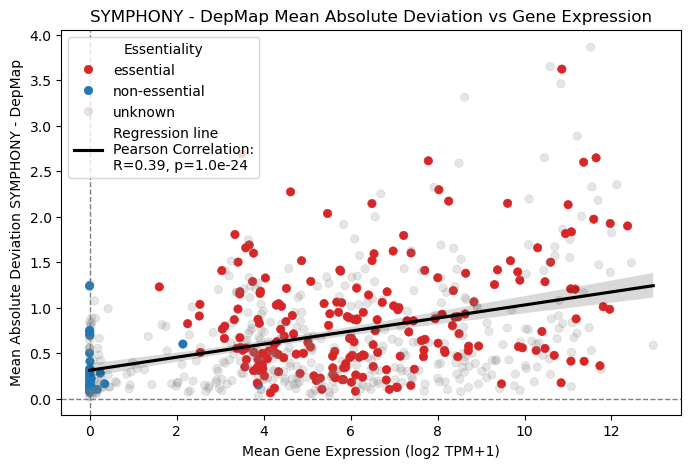

In [67]:
fig, ax = pl.subplots(figsize=(8, 5))
sns.scatterplot(data=super_df_, x='avg_gex', y='MAD_sym_depmap', hue='essentiality',
                palette={'essential': 'tab:red', 'non-essential': 'tab:blue', 'unknown': (0.5, 0.5, 0.5, 0.2)}, 
                hue_order=['essential', 'non-essential', 'unknown'],
                edgecolor=None,
)
# add regression line
# calculate pearson correlation
from scipy.stats import pearsonr
r, p = pearsonr(super_df_['avg_gex'], super_df_['MAD_sym_depmap'])
ax.set_title(f'Pearson R={r:.2f}')
sns.regplot(data=super_df_, x='avg_gex', y='MAD_sym_depmap', ax=ax, scatter=False, 
            color='black', label=f'Regression line\nPearson Correlation:\nR={r:.2f}, p={p:.1e}',
            )
ax.set_xlabel('Mean Gene Expression (log2 TPM+1)')
ax.set_ylabel('Mean Absolute Deviation SYMPHONY - DepMap')
ax.set_title('SYMPHONY - DepMap Mean Absolute Deviation vs Gene Expression')
ax.legend(title='Essentiality', loc='upper left')
ax.axhline(0, color='grey', linestyle='--', linewidth=1, zorder=-1)
ax.axvline(0, color='grey', linestyle='--', linewidth=1, zorder=-1)
pl.savefig(f'../results/figures/depmap_vs_symphony_mad_vs_expression_scatterplot.pdf', bbox_inches='tight', dpi=300)
pl.show()

In [65]:
# Export data
super_df_.to_csv('../results/source_tables/Fig2ce_source_data.csv')